# PENGWIN, semana 10: pipeline completo y ajuste del modelo

Proyecto Integrador Corte 2, Analítica de Datos, UAO 2026-2. Uso exclusivamente académico.

La semana 10 pide el pipeline completo (detección → NMS → segmentación de instancia → clasificación por pertenencia), la distancia de separación, la comparación con SAM y las métricas del §5. Este notebook tiene tres partes:

- **A. Pipeline** (secciones 1-9): cómo se pasa de regiones a fragmentos y a milímetros, y qué da en test.
- **B. Ajuste** (secciones 10-19): todo lo que se probó para acercar la segmentación por fragmento al objetivo, con validación cruzada.
- **C. Decisiones** (secciones 20-21): qué se adoptó, qué se descartó y por qué, y cada vez que se miró el test.

Lee los resultados guardados en `reports/`; no necesita GPU. Con `PENGWIN_CACHE_DIR` y `checkpoints/v2_last/best.pth` rehace la figura del ejemplo de la sección 4.

In [1]:
import json
import os
import sys
import warnings
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.precision", 4)


def find_root(start: Path = Path.cwd()) -> Path:
    for p in [start, *start.parents]:
        if (p / "03_src" / "pengwin").is_dir():
            return p
    raise FileNotFoundError("No se encontró la raíz del repositorio")


ROOT = find_root()
sys.path.insert(0, str(ROOT / "03_src"))
REP = ROOT / "reports"
TUN = REP / "tuning"
FIG_A = REP / "figures" / "semana10"
FIG = REP / "figures" / "semana10_ajuste"
for d in (FIG_A, FIG):
    d.mkdir(parents=True, exist_ok=True)
CACHE = Path(os.environ.get("PENGWIN_CACHE_DIR", ROOT / "data_processed"))
CKPT = ROOT / "checkpoints" / "v2_last" / "best.pth"
try:
    import torch
    HAS_TORCH = True
except ImportError:
    HAS_TORCH = False
LIVE = HAS_TORCH and CKPT.exists() and (CACHE / "084" / "meta.json").exists()

C = {"SA": "#2a78d6", "LI": "#eb6834", "RI": "#1baf7a"}
INK, INK2, MUTED, GRID, AXIS, SURF = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
mpl.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.labelsize": 9,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "legend.frameon": False, "legend.fontsize": 8, "font.size": 9, "lines.linewidth": 2,
})


def savefig(fig, name, carpeta=None):
    fig.savefig((carpeta or FIG) / f"{name}.png", dpi=150, bbox_inches="tight")


def read_json(p):
    return json.loads(Path(p).read_text(encoding="utf-8"))

# Parte A. Pipeline

## 1. Qué hace el pipeline

1. **Corte a corte.** El modelo recibe cada corte con sus vecinos (z−Δ, z, z+Δ, Δ ≈ 2 mm) y da tres salidas: presencia de cada hueso (clasificación), una caja por hueso (grid de stride 8 + NMS propia) y, por píxel, la región (fondo, SA, LI, RI) y la probabilidad de **borde de fractura**.
2. **Volumen.** Las salidas de todos los cortes se apilan en un volumen (Z, 256, 256).
3. **Fragmentos (segunda etapa).** Dentro de cada región se separan los fragmentos (secciones 3-4) y se numeran como en PENGWIN: 1-10 sacro, 11-20 coxal izquierdo, 21-30 coxal derecho; el más grande de cada hueso es el principal.
4. **Grilla nativa.** Se deshace el recorte y el redimensionado para volver al tamaño del `.mha`.
5. **Distancia.** Para cada secundario, la distancia mínima al principal en mm (sección 6).

Es la lógica de dos etapas del §3.2: primero las regiones anatómicas y después los fragmentos dentro de cada región.

## 2. Modelo v2

Segundo entrenamiento (40 épocas en la DGX Spark) con cuatro cambios sobre la semana 9:

- **Borde de fractura en 3D:** antes se calculaba dentro de cada corte y no veía los contactos entre cortes.
- **Dropout espacial** (`Dropout2d`, p = 0,1) en los bloques 3-4 y en el decodificador: apaga canales completos.
- **γ aprendible** en el CBAM, $y = x + \gamma\,(\mathrm{CBAM}(x) - x)$, y en el cuello: mide cuánto usa la red cada parte (sección 9).
- **λ recalibrados** por norma de gradiente, porque la pérdida de borde cambió.

,Base (semana 9),v2
mAP@0.50,0.977,0.980
mAP@[.50:.95],0.841,0.864
IoU_promedio,0.911,0.919
dice_hueso,0.968,0.971
dice_SA,0.954,0.961
cls_f1_macro,0.993,0.993


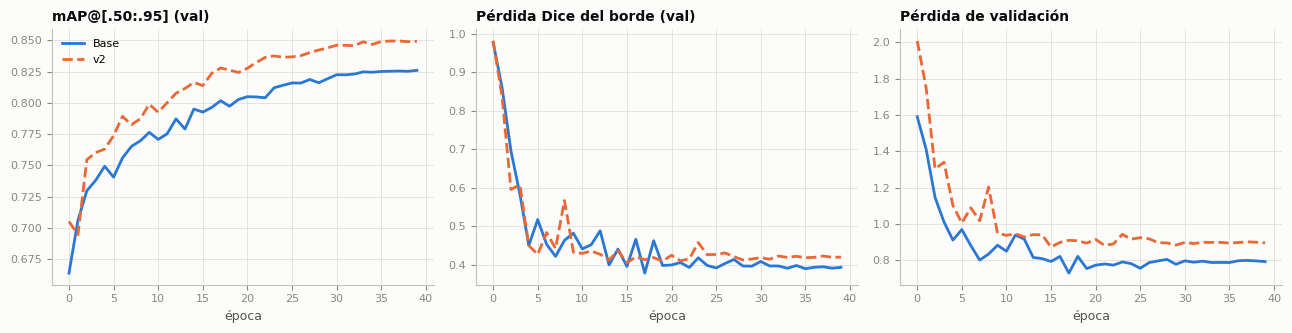

In [2]:
ev = {n: read_json(REP / "eval" / f"{r}_test.json")["metricas"] for r, n in (("base", "Base (semana 9)"), ("v2_last", "v2"))}
keys = ["mAP@0.50", "mAP@[.50:.95]", "IoU_promedio", "dice_hueso", "dice_SA", "cls_f1_macro"]
display(pd.DataFrame({n: {k: m[k] for k in keys} for n, m in ev.items()}).round(3))

H = {n: pd.read_csv(REP / "train" / f"{r}_history.csv") for r, n in (("base", "Base"), ("v2", "v2"))}
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, (col, title) in zip(axes, (("mAP@[.50:.95]", "mAP@[.50:.95] (val)"), ("val_edge_dice", "Pérdida Dice del borde (val)"),
                                   ("val_total", "Pérdida de validación"))):
    for (n, h), (color, ls) in zip(H.items(), ((C["SA"], "-"), (C["LI"], "--"))):
        ax.plot(h.epoch, h[col], color=color, ls=ls, label=n)
    ax.set_title(title, loc="left", fontsize=10)
    ax.set_xlabel("época")
axes[0].legend()
fig.tight_layout()
savefig(fig, "01_curvas_base_v2", FIG_A)
plt.show()

v2 afina mejor las cajas (mAP@[.5:.95] de 0,841 a 0,864 en test). Las pérdidas de validación no se comparan directo, porque el objetivo del borde cambió (3D, con otro peso).

## 3. Por qué no se separaban los fragmentos

Primero se separaba cada hueso quitando los píxeles de borde y tomando los pedazos que quedaran. Casi ningún secundario salía separado (13 % con el modelo base, 10 % con v2). Para encontrar la causa se cruzó lo predicho con lo real, en test (este diagnóstico y la tabla de profundidades de abajo no dejaron archivos versionados, así que sus cifras no se pueden recalcular desde `reports/`):

| Región usada | Borde usado | Secundarios recuperados |
|---|---|---|
| predicha | predicho | 8 % |
| predicha | real | 11 % |
| real | predicho | 12 % |
| real | real | 71 % |

Fallan las dos a la vez: el borde predicho encuentra solo el 15 % del borde real, y la región predicha "rellena" las grietas entre fragmentos y los vuelve a unir.

## 4. Separación por distancia

En vez de depender solo del borde se busca el **centro** de cada fragmento:

1. Núcleo = región sin borde. En cada hueso se calcula la transformada de distancia euclídea con el spacing del vóxel, $d(x) = \min_{y \notin \text{núcleo}} \lVert x - y \rVert_{mm}$ (`distance_transform_edt`).
2. Las zonas con $d > 5$ mm son semillas; cada semilla es un fragmento. Una grieta o un puente delgado nunca llega a 5 mm, así que separa aunque la red lo haya rellenado.
3. Un watershed reparte el resto del hueso entre las semillas.
4. El fragmento más grande es el principal.

Los 5 mm se eligieron en **validación**, no en test:

| Método | Profundidad de semilla | Secundarios recuperados | Dice fragmento |
|---|---|---|---|
| solo borde | — | 1,8 % | 0,531 |
| distancia | 2 mm | 31,0 % | 0,638 |
| distancia | 3 mm | 46,4 % | 0,705 |
| distancia | 4 mm | 61,3 % | 0,765 |
| **distancia** | **5 mm** | **67,3 %** | **0,790** |
| distancia | 6 mm | 59,5 % | 0,764 |
| distancia | 8 mm | 33,3 % | 0,622 |

Poca profundidad deja semillas en los puentes y une fragmentos; mucha profundidad deja a los fragmentos pequeños sin semilla.

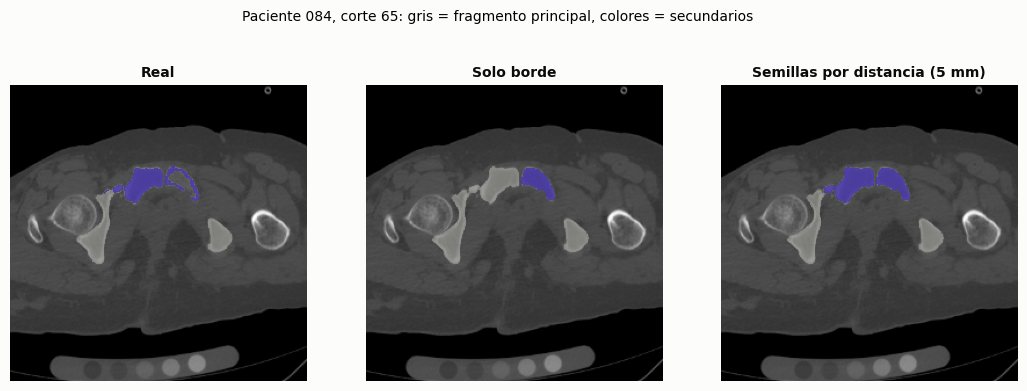

In [3]:
ej_png = FIG_A / "02_ejemplo_fragmentos.png"
if LIVE:
    from matplotlib.colors import ListedColormap
    from pengwin.data.slice_cache import load_case_cache
    from pengwin.inference.volume import predict_case
    from pengwin.models.pengwin_net import PengwinNet
    from pengwin.postprocess.instances import separate_instances

    dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    ck = torch.load(CKPT, map_location="cpu", weights_only=False)
    model = PengwinNet(ck["cfg"]["model"]).to(dev).eval()
    model.load_state_dict(ck["model"])
    case = "084"
    pred = predict_case(model, CACHE, case, ck["cfg"], dev)
    image, label, meta = load_case_cache(CACHE / case)
    sp = (meta["spacing_zyx"][0], meta["pixel_mm"], meta["pixel_mm"])
    solo_borde = separate_instances(pred["semantic"], pred["edge"], sp, 0.5, method="edge")
    distancia = separate_instances(pred["semantic"], pred["edge"], sp, 0.2, method="edt", seed_depth_mm=5.0)
    lab = np.asarray(label)
    z = int(np.argmax([((lab[k] % 10) > 1).sum() for k in range(lab.shape[0])]))   # corte con más secundarios
    cmap = ListedColormap([(0, 0, 0, 0), (0.55, 0.55, 0.53, 0.75), (0.29, 0.23, 0.65, 0.9), (0.91, 0.48, 0.64, 0.9),
                           (0.93, 0.63, 0.0, 0.9), (0.2, 0.2, 0.2, 0.9)])
    rank = lambda L: np.where(L > 0, np.minimum((L - 1) % 10 + 1, 5), 0)
    fig, ax = plt.subplots(1, 3, figsize=(13, 4.6))
    for a, (L, t) in zip(ax, ((lab, "Real"), (solo_borde, "Solo borde"), (distancia, "Semillas por distancia (5 mm)"))):
        a.imshow(np.asarray(image[z]), cmap="gray")
        a.imshow(rank(L[z]), cmap=cmap, vmin=0, vmax=5, interpolation="nearest")
        a.set_title(t, fontsize=10)
        a.axis("off")
    fig.suptitle(f"Paciente {case}, corte {z}: gris = fragmento principal, colores = secundarios", fontsize=10)
    savefig(fig, "02_ejemplo_fragmentos", FIG_A)
    plt.show()
elif ej_png.exists():
    display(Image(filename=str(ej_png), width=950))

## 5. Resultados por fragmento (test)

15 pacientes, 84 fragmentos reales (45 principales y 39 secundarios). Dentro de cada hueso, cada fragmento real se empareja con un predicho maximizando el IoU total (asignación húngara, `linear_sum_assignment`). Un fragmento sin pareja cuenta con Dice 0.

$$\text{IoU} = \frac{|A \cap B|}{|A \cup B|}, \qquad \text{Dice} = \frac{2|A \cap B|}{|A| + |B|} = \frac{2\,\text{IoU}}{1 + \text{IoU}}$$

Las dos se calculan en 3D sobre la grilla nativa, no corte a corte.

In [4]:
rows = {}
for r, name in (("base_test", "Base, solo borde"), ("v2_last_test", "v2, solo borde"),
                ("base_test_edt", "Base, distancia"), ("v2_last_test_edt", "v2, distancia")):
    f = REP / "fragments" / f"{r}.json"
    if f.exists():
        g = read_json(f)["global"]
        rows[name] = {"Dice fragmento": g["dice_fragmento"], "IoU fragmento": g["iou_fragmento"],
                      "Dice principal": g["dice_principal"], "Dice secundario": g["dice_secundario"],
                      "Secundarios recuperados %": g["recuperados_secundarios_%"]}
tabla = pd.DataFrame(rows)
tabla["Objetivo"] = ["≥ 0.85", "≥ 0.70", "", "", ""]
display(tabla.round(3))
f = pd.read_csv(REP / "fragments" / "v2_last_test_edt_fragmentos.csv")
f["tamaño"] = pd.cut(f.volumen_cm3, [0, 5, 20, np.inf], labels=["< 5 cm³", "5-20 cm³", "> 20 cm³"])
f["tipo"] = np.where(f.es_principal, "principal", "secundario")
f.groupby(["tipo", "tamaño"], observed=True).agg(n=("dice", "size"), dice=("dice", "mean"), recuperados=("recuperado", "mean")).round(3)

,"Base, solo borde","v2, solo borde","Base, distancia","v2, distancia",Objetivo
Dice fragmento,0.545,0.533,0.717,0.725,≥ 0.85
IoU fragmento,0.505,0.494,0.657,0.671,≥ 0.70
Dice principal,0.921,0.920,0.920,0.930,
Dice secundario,0.111,0.086,0.483,0.489,
Secundarios recuperados %,12.821,10.256,51.282,51.282,


n   dice  recuperados
tipo       tamaño                          
principal  > 20 cm³  45  0.930        1.000
secundario < 5 cm³    7  0.000        0.000
           5-20 cm³  13  0.506        0.538
           > 20 cm³  19  0.657        0.684

Los principales salen bien (Dice 0,93). El Dice por fragmento (0,725) no llega al 0,85 por los secundarios: se recupera la mitad, y los menores de 5 cm³ no reciben semilla con 5 mm de profundidad. La parte B parte de aquí.

## 6. Distancia de separación en mm

Para cada secundario, $d = \min_{x \in \text{secundario}} \mathrm{EDT}_{\overline{\text{principal}}}(x)$, con `scipy.ndimage.distance_transform_edt(..., sampling=spacing)` y el spacing del header (§3.3). Se mide igual en la predicción y en el ground truth. La EDT va de centro a centro de vóxel: dos fragmentos que se tocan dan ≈ 1 vóxel, por eso "en contacto" es $d \le$ diagonal del vóxel.

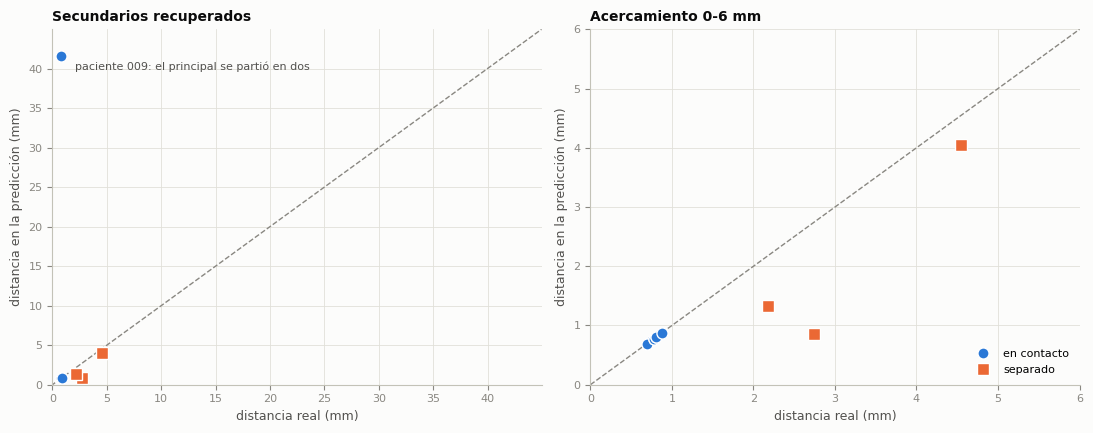

20 secundarios medidos | error medio 2.20 mm | mediana 0.00 mm | sin el caso atípico 0.17 mm


In [5]:
d = pd.read_csv(REP / "fragments" / "v2_last_test_edt_distancias.csv")
dm = d[d.medido]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
for ax, lim in zip(axes, (max(dm.dist_gt_mm.max(), dm.dist_pred_mm.max()) * 1.08, 6)):
    ax.plot([0, lim], [0, lim], color=MUTED, lw=1, ls="--")
    for contacto, marker, name in ((True, "o", "en contacto"), (False, "s", "separado")):
        s = dm[dm.contacto_gt == contacto]
        ax.plot(s.dist_gt_mm, s.dist_pred_mm, marker, ms=8, color=C["SA"] if contacto else C["LI"], mec="white",
                label=name, ls="none")
    ax.set(xlabel="distancia real (mm)", ylabel="distancia en la predicción (mm)", xlim=(0, lim), ylim=(0, lim))
peor = dm.loc[dm.error_mm.abs().idxmax()]
axes[0].annotate(f"paciente {int(peor.case_id):03d}: el principal se partió en dos", (peor.dist_gt_mm, peor.dist_pred_mm),
                 xytext=(10, -4), textcoords="offset points", fontsize=8, color=INK2, va="top")
axes[0].set_title("Secundarios recuperados", loc="left", fontsize=10)
axes[1].set_title("Acercamiento 0-6 mm", loc="left", fontsize=10)
axes[1].legend()
fig.tight_layout()
savefig(fig, "03_distancias", FIG_A)
plt.show()
e = dm.error_mm.abs()
print(f"{len(dm)} secundarios medidos | error medio {e.mean():.2f} mm | mediana {e.median():.2f} mm | "
      f"sin el caso atípico {e.nsmallest(len(e) - 1).mean():.2f} mm")

Casi todo cae sobre la diagonal. El único error grande es un paciente donde el modelo partió en dos el principal y el secundario se midió contra el pedazo equivocado: así pasa un error de segmentación a la medida.

## 7. SAM como línea base

SAM (ViT-B, sin entrenar en nuestros datos) recibe el mismo corte y, como prompt, la caja que predijo nuestro detector (§4.2). Se compara contra la segmentación por hueso del modelo propio. No forma parte del pipeline.

In [6]:
sam = read_json(REP / "sam" / "base_test.json")
display(pd.DataFrame(sam["resultados"]).T[["dice", "iou", "dice_SA", "dice_LI", "dice_RI"]].round(3))
print(f"{sam['cortes_con_hueso']} cortes de test · SAM tarda {sam['ms_sam_por_corte']:.0f} ms por corte")

,dice,iou,dice_SA,dice_LI,dice_RI
propio,0.968,0.938,0.954,0.975,0.974
SAM + caja predicha,0.908,0.832,0.863,0.927,0.932
SAM + caja GT,0.908,0.832,0.866,0.925,0.931


3765 cortes de test · SAM tarda 417 ms por corte


El modelo propio le gana a SAM por 6 puntos de Dice, y por 9 en el sacro. SAM rinde igual con nuestras cajas que con las reales: el detector no es lo que lo limita, es un modelo generalista fuera de su dominio.

## 8. Latencia

Un corte a la vez (como en el slider del dashboard), contando el modelo, la decodificación de cajas y la NMS. La latencia del modelo final, con TTA, está en la sección 19.

In [7]:
lat = read_json(REP / "latency" / "base.json")
display(pd.DataFrame({"CPU fp32": lat["cpu_fp32"], "GPU fp32": lat["gpu_fp32"], "GPU AMP": lat["gpu_amp"]}).T[["media_ms", "p50_ms", "p95_ms"]].round(1))
print(f"GPU: {lat['gpu']} · volumen completo ({lat['cortes_volumen']} cortes): {lat['gpu_volumen_completo_s']:.1f} s")

,media_ms,p50_ms,p95_ms
CPU fp32,101.8,100.7,113.6
GPU fp32,10.2,10.5,13.4
GPU AMP,12.8,12.2,15.5


GPU: NVIDIA GeForce RTX 3060 Laptop GPU · volumen completo (401 cortes): 3.4 s


## 9. Qué aporta cada parte de la red

Dos medidas sobre v2: el **γ** aprendido (cerca de 0 = el componente casi no se usa) y la **caída** al apagar el componente en inferencia.

In [8]:
ct = read_json(REP / "contribucion" / "v2_last.json")
caida = pd.DataFrame(ct["caida_por_knockout"]).T[["mAP@[.50:.95]", "dice_hueso", "dice_SA"]]
caida.index = [i.replace("sin ", "") for i in caida.index]
gam = pd.Series(ct["gammas"], name="γ").rename({"cuello C4": "contexto C4 en P3"})
caida.join(gam).round(3)

,mAP@[.50:.95],dice_hueso,dice_SA,γ
residual b1,-0.042,-0.006,-0.005,0.248
residual b2,-0.027,-0.003,-0.004,0.216
residual b3,-0.033,-0.001,0.001,0.210
CBAM b3,-0.002,-0.000,-0.001,0.182
residual b4,-0.513,-0.176,-0.248,0.322
CBAM b4,-0.068,-0.011,-0.020,-1.898
contexto C4 en P3,-0.793,-0.335,-0.474,0.717
contexto 2.5D,-0.043,-0.019,-0.021,NaN


- El CBAM del bloque 3 casi no se usa (γ ≈ 0,18; apagarlo no cambia nada). El del bloque 4 sí (γ ≈ −1,9): con γ negativo la salida es $2{,}9\,x - 1{,}9\,\mathrm{CBAM}(x)$, es decir, la red **resta** lo que la atención resalta y refuerza el resto. No es "atención apagada", es atención usada al revés.
- Lo indispensable es el bloque residual 4 y el contexto profundo que entra al cuello.
- Apagar una parte mide cuánto **depende** la red de ella, no cuánto **aporta**: el modelo entrenado sin CBAM llega al mismo resultado (sección 16).

# Parte B. Ajuste

Las métricas de esta parte se calculan sobre las predicciones fuera de fold en la grilla de 256 px del modelo (contra `label.npy` del caché); el test de la parte A se mide en la grilla nativa. Medidas en la grilla nativa, las mismas predicciones de la configuración final dan 0,786 / 0,707 de Dice / IoU por fragmento en vez de 0,792 / 0,717 (`03_semana11` §1.2). Las comparaciones entre candidatos son válidas porque todos se miden igual.

Todo sale de tres archivos consolidados en `reports/tuning/` (`ajuste_posproceso.csv.gz`, `ajuste_corridas.csv.gz`, `ajuste_borde.csv`), que arma `scripts/consolidar_ajuste.py` a partir de los resultados crudos de la DGX Spark (107,8 h de GPU sumando todas las corridas).

In [9]:
# Resultados consolidados y funciones de comparación
M_FRAG = ["dice_fragmento", "iou_fragmento", "dice_principal", "dice_secundario", "recuperados_secundarios_%"]
NOMBRES = {"dice_fragmento": "Dice frag", "iou_fragmento": "IoU frag", "dice_principal": "Dice principal",
           "dice_secundario": "Dice secundario", "recuperados_secundarios_%": "Secundarios %"}


# Resultados consolidados (scripts/consolidar_ajuste.py): los crudos no van a git.
PP_ALL = pd.read_csv(TUN / "ajuste_posproceso.csv.gz")
CORR = pd.read_csv(TUN / "ajuste_corridas.csv.gz")
BORDE = pd.read_csv(TUN / "ajuste_borde.csv")


def pp(nombre):
    """Barrido de posproceso de un experimento: una fila por (combinación, fold)."""
    d = PP_ALL[PP_ALL.experimento == nombre].dropna(axis=1, how="all")
    return d if len(d) else None


def historial(corrida):
    """Historial por época de un entrenamiento de CV (None si no existe)."""
    d = CORR[CORR.corrida == corrida]
    return d if len(d) else None


def borde(corrida, umbral=0.2):
    """Precisión y recall de la cabeza de borde contra edge.npy (fold 0)."""
    d = BORDE[(BORDE.corrida == corrida) & (BORDE.referencia == "edge.npy") & (BORDE.umbral == umbral)]
    return d.iloc[0] if len(d) else None


def mejor(nombre, metrica="dice_fragmento", filtro=None):
    """Combinación con la mejor media entre folds: filas por fold y sus parámetros."""
    df = pp(nombre)
    if df is None:
        return None, None
    if filtro:
        df = df.query(filtro)
    c = df.groupby("combo")[metrica].mean().idxmax()
    filas = df[df.combo == c].set_index("fold").sort_index()
    params = {k: filas.iloc[0][k] for k in ("method", "seed_depth_mm", "edge_threshold", "hmax_h_mm") if k in filas}
    return filas, params


def pareado(a, b, metrica="dice_fragmento"):
    """Diferencia emparejada por fold (a − b): media, desviación, t y folds a favor."""
    d = (a[metrica] - b[metrica]).dropna()
    n = len(d)
    sd = d.std(ddof=1) if n > 1 else np.nan
    t = d.mean() / (sd / np.sqrt(n)) if n > 1 and sd > 0 else np.nan
    return {"Δ": d.mean(), "desv Δ": sd, "t": t, "folds a favor": f"{int((d > 0).sum())}/{n}"}

## 10. Punto de partida

Modelo `v2_last` (40 épocas) con el posproceso por distancia de la sección 4, frente a los objetivos del §5.

In [10]:
ev = read_json(REP / "eval" / "v2_last_test.json")["metricas"]
fr = read_json(REP / "fragments" / "v2_last_test_edt.json")["global"]
filas = [
    ("Clasificación", "F1", ev["cls_f1_macro"], 0.85),
    ("Clasificación", "AUC", ev["cls_auc_macro"], 0.85),
    ("Detección", "IoU promedio", ev["IoU_promedio"], 0.65),
    ("Detección", "mAP@0.50", ev["mAP@0.50"], 0.65),
    ("Detección", "mAP@[.50:.95]", ev["mAP@[.50:.95]"], 0.40),
    ("Segmentación de fragmento", "Dice", fr["dice_fragmento"], 0.85),
    ("Segmentación de fragmento", "IoU", fr["iou_fragmento"], 0.70),
]
inicio = pd.DataFrame(filas, columns=["Tarea", "Métrica", "Test", "Objetivo"])
inicio["Cumple"] = np.where(inicio.Test >= inicio.Objetivo, "sí", "no")
inicio["Falta"] = (inicio.Objetivo - inicio.Test).clip(lower=0)
inicio.round(3)

,Tarea,Métrica,Test,Objetivo,Cumple,Falta
0,Clasificación,F1,0.993,0.85,sí,0.000
1,Clasificación,AUC,0.999,0.85,sí,0.000
2,Detección,IoU promedio,0.919,0.65,sí,0.000
3,Detección,mAP@0.50,0.980,0.65,sí,0.000
4,Detección,mAP@[.50:.95],0.864,0.40,sí,0.000
5,Segmentación de fragmento,Dice,0.725,0.85,no,0.125
6,Segmentación de fragmento,IoU,0.671,0.70,no,0.029


Detección y clasificación sobran. Lo que falta es la segmentación por **fragmento**: 0,125 de Dice y 0,029 de IoU.

El Dice por fragmento se calcula sobre cada fragmento real: se empareja con el predicho que más se le parece, y si no tiene pareja cuenta como 0. Por eso pesa tanto un fragmento pequeño que no se detecta.

## 11. Cómo medimos

Reglas que se fijaron antes de empezar, para no engañarnos con las métricas:

- **En esta fase el test no se usa para elegir nada.** Solo se mide al final, una vez (antes del ajuste hubo dos decisiones que sí lo miraron; ver sección 21).
- **Validación cruzada por paciente:** los 85 casos de train+val en 5 folds de 17 pacientes. Cada modelo predice los pacientes que no vio en su entrenamiento (predicciones *fuera de fold*), y sobre esas predicciones se ajusta el posproceso sin reentrenar.
- **Comparaciones emparejadas por fold:** cada candidato contra la referencia en los mismos pacientes.
- **Ruido de semilla:** entrenamos la misma configuración con semillas distintas. Una diferencia más chica que ese ruido no cuenta como mejora.

Primero el ruido. Cuatro entrenamientos idénticos (12 épocas, fold 0) que solo cambian la semilla:

In [11]:
semillas = {}
for nombre, s in (("cv_c00_base_e12_f0", 42), ("cv_c00b_seed1337_e12_f0", 1337),
                  ("cv_c00c_seed2024_e12_f0", 2024), ("cv_c00c_seed7_e12_f0", 7)):
    f, p = mejor(f"pp_scr_{nombre}")
    semillas[s] = {**{NOMBRES[m]: f[m].iloc[0] for m in M_FRAG[:2]}, "profundidad óptima (mm)": p["seed_depth_mm"]}
semillas = pd.DataFrame(semillas).T
semillas.index.name = "semilla"
SIGMA12 = semillas["Dice frag"].std(ddof=1)
display(semillas.round(4))
print(f"σ entre semillas (Dice por fragmento, 12 épocas, 1 fold): {SIGMA12:.4f}  ->  umbral 2σ = {2 * SIGMA12:.4f}")

,Dice frag,IoU frag,profundidad óptima (mm)
semilla,,,
42,0.6925,0.6296,4.0
1337,0.6700,0.5914,6.0
2024,0.6770,0.6052,6.0
7,0.6746,0.5981,6.0


σ entre semillas (Dice por fragmento, 12 épocas, 1 fold): 0.0097  ->  umbral 2σ = 0.0195


Solo cambiando la semilla, el Dice por fragmento se mueve 0,0225 entre la mejor y la peor corrida. Ese es el tamaño del ruido contra el que se compara todo lo demás.

A 20 épocas y con 5 folds emparejados se midió igual: la misma configuración con semilla 1337 contra la de semilla 42 da Δ medio 0,000 con desviación por fold de 0,013, con el posproceso fijo. Si a cada una se le elige su mejor combinación de posproceso, como en la tabla de la sección 15, la diferencia es −0,0007.

## 12. Posproceso

El posproceso parte cada hueso en fragmentos. Dos parámetros importan: la **profundidad de semilla** (a cuántos mm del borde empieza un fragmento) y el **umbral de borde** (desde qué probabilidad un píxel cuenta como borde de fractura). Se barrieron sobre las predicciones fuera de fold del modelo base (20 épocas, 5 folds):

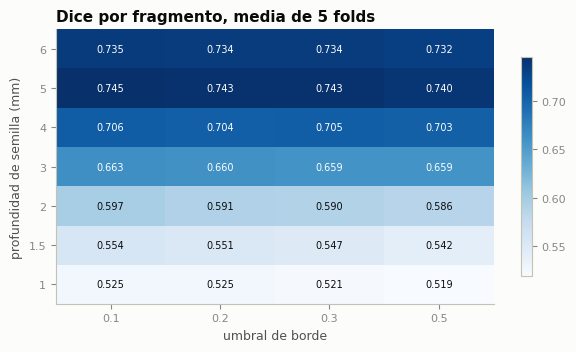

,solo borde (edge),distancia (edt)
Dice frag,0.498,0.745
IoU frag,0.460,0.683
Dice principal,0.909,0.921
Dice secundario,0.052,0.556
Secundarios %,4.923,59.510


In [12]:
b = pp("pp1_base_e20").query("method == 'edt'")
mapa = b.groupby(["seed_depth_mm", "edge_threshold"]).dice_fragmento.mean().unstack()
fig, ax = plt.subplots(figsize=(6.2, 3.6))
im = ax.imshow(mapa.values, cmap="Blues", aspect="auto", origin="lower")
ax.set_xticks(range(mapa.shape[1]), [f"{x:g}" for x in mapa.columns])
ax.set_yticks(range(mapa.shape[0]), [f"{y:g}" for y in mapa.index])
ax.set(xlabel="umbral de borde", ylabel="profundidad de semilla (mm)")
ax.set_title("Dice por fragmento, media de 5 folds", loc="left")
ax.grid(False)
for i in range(mapa.shape[0]):
    for j in range(mapa.shape[1]):
        v = mapa.values[i, j]
        ax.text(j, i, f"{v:.3f}", ha="center", va="center", fontsize=7, color="white" if v > mapa.values.mean() else INK)
fig.colorbar(im, ax=ax, shrink=0.8)
fig.tight_layout()
savefig(fig, "01_posproceso_mapa")
plt.show()

edge, _ = mejor("pp1_base_e20_edge")
edt, _ = mejor("pp1_base_e20")
pd.DataFrame({"solo borde (edge)": edge[M_FRAG].mean(), "distancia (edt)": edt[M_FRAG].mean()}).rename(index=NOMBRES).round(3)

- El mejor valor está en 5 mm, que es el que ya usábamos. Los umbrales vecinos a esa profundidad (0,2 y 0,3) quedan a menos de 0,003; la profundidad sí pesa: 6 mm baja 0,010 y 4 mm baja 0,040.
- El umbral de borde casi no cambia nada (columnas casi iguales). Es una pista: el borde predicho casi nunca pasa de 0,1, así que da igual dónde se corte.
- Separar por distancia (`edt`) en vez de solo por borde vale +0,247 de Dice. Es la mejora más grande del proyecto, y ya estaba en el modelo de la semana 10.

El posproceso estaba bien elegido; no queda ganancia ahí.

## 13. Dónde está el error

Para saber qué parte del modelo frena el Dice, se cambiaron por el ground truth, por separado, sus dos salidas: la **región** (qué hueso es cada píxel) y el **borde de fractura**.

,Dice frag,IoU frag,Dice principal,Dice secundario,Secundarios %,profundidad (mm)
modelo real,0.745,0.683,0.921,0.556,59.510,5.0
región real + borde predicho,0.770,0.729,0.947,0.578,59.572,5.0
región predicha + borde real,0.902,0.856,0.958,0.841,90.586,3.0
región real + borde real,0.989,0.984,0.999,0.979,99.100,2.0


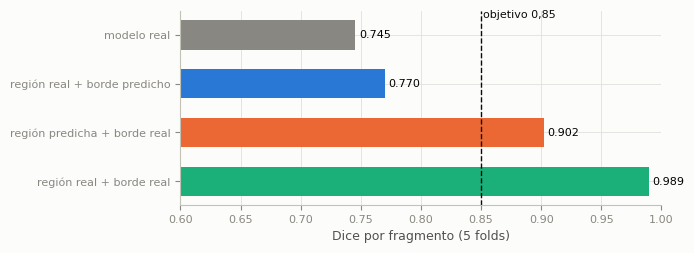

In [13]:
casos = {
    "modelo real": "pp1_base_e20",
    "región real + borde predicho": "pp_hib_gtsem_prededge",
    "región predicha + borde real": "pp_hib_predsem_gtedge",
    "región real + borde real": "pp_oraculo_gt",
}
filas = {}
for k, n in casos.items():
    f, p = mejor(n)
    filas[k] = {**{NOMBRES[m]: f[m].mean() for m in M_FRAG}, "profundidad (mm)": p["seed_depth_mm"]}
hib = pd.DataFrame(filas).T
display(hib.round(3))

fig, ax = plt.subplots(figsize=(7, 2.6))
y = np.arange(len(hib))[::-1]
ax.barh(y, hib["Dice frag"], color=[MUTED, C["SA"], C["LI"], C["RI"]], height=0.6)
ax.axvline(0.85, color=INK, ls="--", lw=1)
ax.text(0.852, y[0] + 0.35, "objetivo 0,85", fontsize=8, color=INK)
ax.set_yticks(y, hib.index)
ax.set_xlim(0.6, 1.0)
ax.set_xlabel("Dice por fragmento (5 folds)")
for yi, v in zip(y, hib["Dice frag"]):
    ax.text(v + 0.003, yi, f"{v:.3f}", va="center", fontsize=8)
fig.tight_layout()
savefig(fig, "02_donde_esta_el_error")
plt.show()

In [14]:
BORDE.query("corrida == 'cv_c00_base_e12_f0' and referencia == 'edge.npy'").set_index("umbral")[["precision", "recall"]].round(3)

,precision,recall
umbral,,
0.1,0.344,0.177
0.2,0.352,0.164
0.3,0.358,0.156
0.5,0.368,0.144


- Con el **borde real**, el Dice sube de 0,745 a 0,902 (+0,157). Con la **región real**, apenas +0,025. El problema es la cabeza de borde, seis veces más que la región.
- La cabeza de borde encuentra **menos del 20 %** de la superficie de fractura real (recall), y bajar el umbral casi no lo sube: el resto no está "casi detectado", está en cero.
- Con el borde real ya se pasaría el 0,85. Todo lo que sigue intenta mejorar ese borde.

## 14. Cribado de hiperparámetros (12 épocas)

Diez cambios de entrenamiento, cada uno contra la referencia, todos con 12 épocas en el fold 0. A cada uno se le buscó su mejor posproceso, igual que a las semillas.

,Dice frag,Δ,IoU frag,Secundarios %,precisión borde,recall borde,Δ/σ,cambio
c05_oversample3,0.7031,0.0106,0.6447,52.7273,0.4544,0.1866,1.0854,repetir ×3 cortes con fragmentos secundarios
c06_lr1e3,0.6963,0.0038,0.6197,52.7273,0.3988,0.1711,0.3890,lr 1e-3 (base 3e-4)
c03_edge_d1,0.6939,0.0014,0.6320,52.7273,0.3908,0.1152,0.1434,borde más fino (dilatación 1)
c00_base,0.6925,0.0000,0.6296,47.2727,0.3522,0.1643,0.0000,referencia (semilla 42)
c01_posw4,0.6908,-0.0017,0.6270,47.2727,0.3652,0.1571,-0.1693,peso del borde 4 (base 9)
c08_sdrop02,0.6905,-0.0020,0.6294,50.9091,0.3233,0.1844,-0.2066,"dropout espacial 0,2 (base 0,1)"
c07_sdrop0,0.6891,-0.0034,0.6222,50.9091,0.4098,0.1650,-0.3460,sin dropout espacial
c04_edge_d3,0.6875,-0.0049,0.6247,49.0909,0.3047,0.1882,-0.5078,borde más grueso (dilatación 3)
c02_posw16,0.6835,-0.0090,0.6217,45.4545,0.3436,0.1532,-0.9245,peso del borde 16
c09_augstrong,0.6805,-0.0120,0.6182,49.0909,0.3179,0.1868,-1.2330,aumentación fuerte


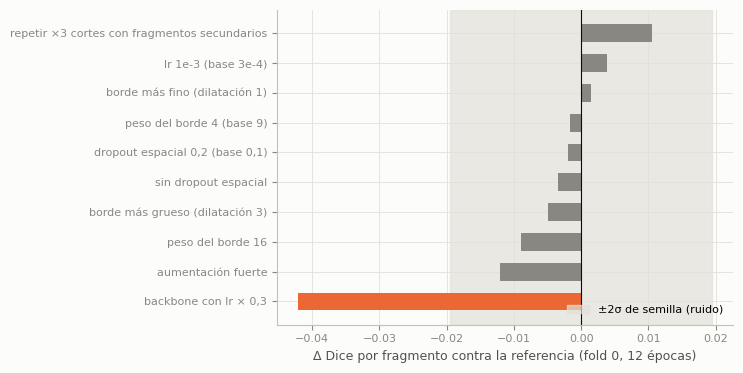

In [15]:
CANDIDATOS = {
    "c00_base": "referencia (semilla 42)",
    "c01_posw4": "peso del borde 4 (base 9)",
    "c02_posw16": "peso del borde 16",
    "c03_edge_d1": "borde más fino (dilatación 1)",
    "c04_edge_d3": "borde más grueso (dilatación 3)",
    "c05_oversample3": "repetir ×3 cortes con fragmentos secundarios",
    "c06_lr1e3": "lr 1e-3 (base 3e-4)",
    "c07_sdrop0": "sin dropout espacial",
    "c08_sdrop02": "dropout espacial 0,2 (base 0,1)",
    "c09_augstrong": "aumentación fuerte",
    "c10_bblr03": "backbone con lr × 0,3",
}
ref, _ = mejor("pp_scr_cv_c00_base_e12_f0")
filas = {}
for c, desc in CANDIDATOS.items():
    f, p = mejor(f"pp_scr_cv_{c}_e12_f0")
    rb = borde(f"cv_{c}_e12_f0")
    rb = {} if rb is None else rb.to_dict()
    filas[c] = {"cambio": desc, "Dice frag": f.dice_fragmento.iloc[0], "Δ": f.dice_fragmento.iloc[0] - ref.dice_fragmento.iloc[0],
                "IoU frag": f.iou_fragmento.iloc[0], "Secundarios %": f["recuperados_secundarios_%"].iloc[0],
                "precisión borde": rb.get("precision"), "recall borde": rb.get("recall")}
crib = pd.DataFrame(filas).T
crib["Δ/σ"] = crib["Δ"].astype(float) / SIGMA12
crib = crib.sort_values("Dice frag", ascending=False)
display(crib.drop(columns="cambio").astype(float).round(4).join(crib.cambio))

fig, ax = plt.subplots(figsize=(7.5, 3.8))
d = crib.drop("c00_base")["Δ"].astype(float)[::-1]
ax.axvspan(-2 * SIGMA12, 2 * SIGMA12, color=GRID, alpha=0.7, label="±2σ de semilla (ruido)")
ax.barh(range(len(d)), d, color=[C["RI"] if v > 2 * SIGMA12 else (C["LI"] if v < -2 * SIGMA12 else MUTED) for v in d], height=0.6)
ax.set_yticks(range(len(d)), [CANDIDATOS[i] for i in d.index])
ax.axvline(0, color=INK, lw=0.8)
ax.set_xlabel("Δ Dice por fragmento contra la referencia (fold 0, 12 épocas)")
ax.legend(loc="lower right")
fig.tight_layout()
savefig(fig, "03_cribado")
plt.show()

- Nueve de los diez caen dentro de la banda de ruido: lo que se ve entre ellos es la semilla, no el cambio.
- El único efecto claro es **negativo**: frenar el backbone preentrenado (lr × 0,3) baja 0,042. El backbone necesita adaptarse por completo.
- El mejor fue `c05` (repetir los cortes con secundarios), +0,011, que todavía es ruido. Pasó a confirmarse con 5 folds.

## 15. Confirmación con 5 folds (20 épocas)

Aquí se compara con más poder: 5 folds emparejados, 20 épocas. Además de hiperparámetros se probaron cambios de **arquitectura** dentro de lo que permite el enunciado:

- **Núcleo/borde (F2B1):** en vez de un mapa de borde, la cabeza predice 3 clases (fondo, núcleo, borde), como el ganador de PENGWIN 2024.
- **Mapa de distancia (F2B2):** la cabeza predice a cuántos mm está cada píxel de la fractura.
- **Semillas por h-máxima (F2C1, F2C2):** cambios solo de posproceso para no perder fragmentos pequeños.

Los modelos con otra semilla (1337) se comparan contra la referencia de semilla 1337.

In [16]:
# (nombre, archivo, referencia, filtro del candidato, filtro de la referencia)
# F2C2 cambia solo el posproceso: se compara contra edt con la MISMA profundidad y umbral, para aislar el método.
IGUAL = "method == 'edt' and seed_depth_mm == 5 and edge_threshold == 0.1"
EXP = [
    ("Control: misma config, semilla 1337", "pp1_c00b_seed1337_e20", "pp1_base_e20", None, None),
    ("c05 repetir cortes con secundarios", "pp1_c05_oversample3_e20", "pp1_base_e20", None, None),
    ("Sin transfer learning (semilla 42)", "pp_f2a_sintl", "pp1_base_e20", None, None),
    ("Sin transfer learning (semilla 1337)", "pp_f2a_s1337", "pp1_c00b_seed1337_e20", None, None),
    ("Sin CBAM", "pp_abl_nocbam", "pp1_base_e20", None, None),
    ("F2B1 núcleo/borde, su método", "pp_f2b1_core3", "pp1_base_e20", None, None),
    ("F2B1, mismo modelo con posproceso edt", "pp_f2b1_con_edt", "pp1_base_e20", None, None),
    ("F2B2 mapa de distancia, su método", "pp_f2b2_dist", "pp1_base_e20", None, None),
    ("F2B2, mismo modelo con posproceso edt", "pp_f2b2_con_edt", "pp1_base_e20", None, None),
    ("F2C1 semillas h-máxima", "pp_hmax_base_e20", "pp1_base_e20", None, None),
    ("F2C2 edt + h-máxima (semilla 42)", "pp_edthmax_base_e20", "pp1_base_e20", "hmax_h_mm == 1.0 and seed_depth_mm == 5", IGUAL),
    ("F2C2 con h = 1,5 (semilla 42)", "pp_edthmax_base_e20", "pp1_base_e20", "hmax_h_mm == 1.5 and seed_depth_mm == 5", IGUAL),
    ("F2C2 edt + h-máxima (semilla 1337)", "pp_edthmax_rep1337", "pp1_c00b_seed1337_e20", "hmax_h_mm == 1.0", IGUAL),
    ("F2C2 con h = 1,5 (semilla 1337)", "pp_edthmax_rep1337", "pp1_c00b_seed1337_e20", "hmax_h_mm == 1.5", IGUAL),
]
base_f, _ = mejor("pp1_base_e20")
filas, PF = {}, {}
for nombre, arch, refn, filtro, rfiltro in EXP:
    f, _ = mejor(arch, filtro=filtro)
    if f is None:
        continue
    r, _ = mejor(refn, filtro=rfiltro)
    pr = pareado(f, r)
    PF[nombre] = (f.dice_fragmento - r.dice_fragmento)
    filas[nombre] = {"Dice frag": f.dice_fragmento.mean(), "IoU frag": f.iou_fragmento.mean(),
                     "Dice principal": f.dice_principal.mean(), "Secundarios %": f["recuperados_secundarios_%"].mean(),
                     "Δ Dice": pr["Δ"], "t": pr["t"], "folds a favor": pr["folds a favor"],
                     "Δ IoU": pareado(f, r, "iou_fragmento")["Δ"], "Δ principal": pareado(f, r, "dice_principal")["Δ"]}
conf = pd.DataFrame(filas).T
ref_row = pd.DataFrame({"Dice frag": base_f.dice_fragmento.mean(), "IoU frag": base_f.iou_fragmento.mean(),
                        "Dice principal": base_f.dice_principal.mean(),
                        "Secundarios %": base_f["recuperados_secundarios_%"].mean()}, index=["Referencia (base, semilla 42)"])
display(pd.concat([ref_row, conf]).round(4).fillna(""))

,Dice frag,IoU frag,Dice principal,Secundarios %,Δ Dice,t,folds a favor,Δ IoU,Δ principal
"Referencia (base, semilla 42)",0.7453,0.6828,0.9206,59.5101,,,,,
"Control: misma config, semilla 1337",0.7446,0.6687,0.8973,58.9398,-0.0007,-0.1182,3/5,-0.0142,-0.0233
c05 repetir cortes con secundarios,0.7540,0.6939,0.9242,62.3802,0.0087,0.943,3/5,0.011,0.0035
Sin transfer learning (semilla 42),0.7594,0.6969,0.9245,62.7773,0.0141,1.0396,3/5,0.014,0.0039
Sin transfer learning (semilla 1337),0.7522,0.6903,0.9242,60.8949,0.0076,0.6003,3/5,0.0216,0.0269
Sin CBAM,0.7365,0.6744,0.9197,56.3262,-0.0088,-0.9245,1/5,-0.0085,-0.0009
"F2B1 núcleo/borde, su método",0.6729,0.6253,0.9255,41.2824,-0.0724,-3.1253,1/5,-0.0575,0.0049
"F2B1, mismo modelo con posproceso edt",0.7461,0.6737,0.9023,58.3526,0.0008,0.0993,3/5,-0.0091,-0.0183
"F2B2 mapa de distancia, su método",0.5039,0.4680,0.9151,5.7422,-0.2414,-10.8826,0/5,-0.2148,-0.0055
"F2B2, mismo modelo con posproceso edt",0.7298,0.6686,0.9146,53.6832,-0.0155,-1.0735,1/5,-0.0143,-0.0061


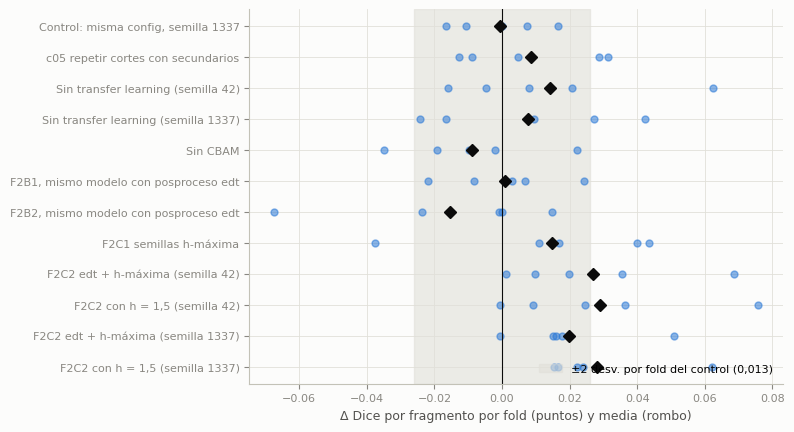

,mAP50,mAP5095,iou_caja,F1,AUC,decision
id,,,,,,
P1-base,0.9785,0.8438,0.9111,0.9905,0.9987,referencia
P4-c05,0.9812,0.8718,0.9217,0.9926,0.9990,"NO se adopta: 1.60 sigma, 3/5 folds"
P4-ctrl,0.9772,0.8362,0.9079,0.9896,0.9984,control: sigma por fold 0.0130
F2A,0.9767,0.8312,0.9059,0.9881,0.9975,no confirma con la replica (ver F2A-rep): NO s...
F2B1,0.9791,0.8587,0.9168,0.9917,0.9989,RECHAZADO: -0.072 vs base
F2B1-ctrl,0.9791,0.8587,0.9168,0.9917,0.9989,"control: el modelo es igual al base (+0.0005),..."
F2A-rep,0.9771,0.8254,0.9040,0.9900,0.9984,"no confirma: agrupado t=1.19, 6/10 folds -> LI..."
F2B2,0.9823,0.8925,0.9301,0.9934,0.9992,"RECHAZADO: 0.5039, rec 5.7%, plano en todos lo..."
F2B2-ctrl,0.9823,0.8925,0.9301,0.9934,0.9992,control: modelo algo peor que base (-0.0155)


In [17]:
fig, ax = plt.subplots(figsize=(8, 4.4))
nombres = [n for n in PF if "su método" not in n]
for i, n in enumerate(nombres[::-1]):
    d = PF[n]
    ax.plot(d.values, [i] * len(d), "o", color=C["SA"], alpha=0.55, ms=5)
    ax.plot(d.mean(), i, "D", color=INK, ms=6)
ax.axvline(0, color=INK, lw=0.8)
ax.axvspan(-0.026, 0.026, color=GRID, alpha=0.6, label="±2 desv. por fold del control (0,013)")
ax.set_yticks(range(len(nombres)), nombres[::-1])
ax.set_xlabel("Δ Dice por fragmento por fold (puntos) y media (rombo)")
ax.legend(loc="lower right")
fig.tight_layout()
savefig(fig, "04_confirmacion_por_fold")
plt.show()

exp_csv = pd.read_csv(TUN / "fase2" / "EXPERIMENTOS.csv")
exp_csv.set_index("id")[["mAP50", "mAP5095", "iou_caja", "F1", "AUC", "decision"]]

Cómo leer la tabla: `t` es la diferencia media dividida por su error. Con 5 folds hace falta |t| > 2,78 para que sea significativa al 5 %.

- **c05** mejora +0,009, pero no alcanza (t = 0,94, 3/5 folds). No se adopta.
- **Núcleo/borde (F2B1)** y **mapa de distancia (F2B2)** empeoran mucho con su propio método (−0,07 y −0,24). Con el posproceso de siempre, esos mismos modelos quedan iguales a la referencia. O sea: la red aprendió lo mismo, lo que no sirvió fue la nueva representación.
- **F2C1** (solo h-máximas) sube el Dice +0,015 pero el principal cae 0,043 y el IoU no se mueve: parte de más.
- **F2C2** (posproceso híbrido) es lo único que sube de forma consistente: +0,020 a +0,029 de Dice y +0,010 a +0,017 de IoU, en 4 o 5 de 5 folds y en dos modelos distintos. Tiene un costo pequeño y parejo: el Dice del fragmento principal baja ~0,010, porque las semillas nuevas le quitan algo de borde. La regla fijada de antemano no permitía bajar más de 0,010; con h = 1,0 una réplica se pasó del límite por 0,0012 y por eso no se adoptó en su momento. Se retoma en la sección 19.
- Para F2C2 la referencia es el mismo modelo con `edt` a la misma profundidad (5 mm) y umbral (0,1): así se mide solo el cambio de método.
- Ningún cambio toca la detección ni la clasificación (última tabla): todas siguen muy por encima del objetivo.

## 16. Ablaciones del informe: CBAM y transfer learning

El enunciado (§7) pide el estudio con/sin CBAM y con/sin transfer learning. En la semana 9 se midieron en test con una sola semilla. Ahora están por validación cruzada.

In [18]:
abl = conf.loc[["Sin CBAM", "Sin transfer learning (semilla 42)", "Sin transfer learning (semilla 1337)"],
               ["Dice frag", "IoU frag", "Δ Dice", "t", "folds a favor"]]
display(abl.round(4))
sintl = pd.concat([PF["Sin transfer learning (semilla 42)"], PF["Sin transfer learning (semilla 1337)"]])
t10 = sintl.mean() / (sintl.std(ddof=1) / np.sqrt(len(sintl)))
print(f"Sin TL, las dos semillas juntas (10 pares): Δ = {sintl.mean():+.4f}, t = {t10:.2f} (crítico 2,26), "
      f"{int((sintl > 0).sum())}/10 a favor")
print("Δ por fold, semilla 42:  ", PF["Sin transfer learning (semilla 42)"].round(3).tolist())
print("Δ por fold, semilla 1337:", PF["Sin transfer learning (semilla 1337)"].round(3).tolist())

,Dice frag,IoU frag,Δ Dice,t,folds a favor
Sin CBAM,0.7365,0.6744,-0.0088,-0.9245,1/5
Sin transfer learning (semilla 42),0.7594,0.6969,0.0141,1.0396,3/5
Sin transfer learning (semilla 1337),0.7522,0.6903,0.0076,0.6003,3/5


Sin TL, las dos semillas juntas (10 pares): Δ = +0.0108, t = 1.23 (crítico 2,26), 6/10 a favor
Δ por fold, semilla 42:   [0.008, 0.063, 0.021, -0.005, -0.016]
Δ por fold, semilla 1337: [0.009, 0.042, 0.027, -0.017, -0.024]


- **CBAM:** quitarlo baja 0,009, dentro del ruido. No hay efecto medible sobre los fragmentos. Se mantiene porque el enunciado lo exige.
- **Transfer learning:** sin TL sale +0,014 con una semilla y +0,008 con otra. Juntas, t = 1,2: no hay diferencia. Los pesos del Taller 3 no ayudan ni estorban.
- Detalle que vale para el informe: el efecto depende del **paciente**, no de la semilla. El fold 1 gana sin TL en las dos semillas (+0,063 y +0,042) y los folds 3-4 pierden en las dos. Hay un subgrupo de pacientes al que le va mejor sin TL, pero en promedio da igual.

## 17. Dropout espacial de 0 a 0,40

El modelo usa `Dropout2d` (apaga canales enteros) con p = 0,1 en los bloques 3-4 del backbone y en el decodificador. La cabeza de borde sobreajusta (pérdida de borde en train 0,23 contra 0,43 en val, media de los 5 folds a 20 épocas), y el dropout es la herramienta directa contra eso. Ya se había probado 0 y 0,2; faltaba el rango alto.

Cómo se probó: mismo valor en los dos sitios (`spatial_dropout` y `seg_spatial_dropout`), 12 épocas, en el **fold 0**, donde ya estaban medidos 0, 0,1, 0,2 y las 4 semillas de referencia. Así la curva de 0 a 0,40 sale completa y comparable. Los cambios de cada corrida quedan en `ajuste_corridas.csv.gz` (`sd025` a `sd040`).

Una segunda tanda en el fold 2 quedó preparada pero no se corrió, para liberar la GPU.

In [19]:
DROP = {0.0: "c07_sdrop0", 0.1: "c00_base", 0.2: "c08_sdrop02", 0.25: "sd025", 0.30: "sd030", 0.35: "sd035", 0.40: "sd040"}
filas = []
for fold in (0,):
    for p, n in DROP.items():
        f, prm = mejor(f"pp_scr_cv_{n}_e12_f{fold}")
        h = historial(f"cv_{n}_e12_f{fold}")
        hist = h.iloc[-1] if h is not None else None
        if f is None:
            continue
        filas.append({"fold": fold, "p": p, "Dice frag": f.dice_fragmento.iloc[0], "IoU frag": f.iou_fragmento.iloc[0],
                      "Secundarios %": f["recuperados_secundarios_%"].iloc[0],
                      "pérdida borde train": hist["train_edge_dice"] if hist is not None else np.nan,
                      "pérdida borde val": hist["val_edge_dice"] if hist is not None else np.nan,
                      "mAP@[.5:.95]": hist["mAP@[.50:.95]"] if hist is not None else np.nan,
                      "Dice región": hist["dice_hueso"] if hist is not None else np.nan})
drop = pd.DataFrame(filas)
if drop.empty or drop.p.max() < 0.25:
    print("Pendiente: el barrido de dropout todavía está corriendo en la DGX Spark.")
else:
    drop["brecha borde (val − train)"] = drop["pérdida borde val"] - drop["pérdida borde train"]
    display(drop.round(4))

,fold,p,Dice frag,IoU frag,Secundarios %,pérdida borde train,pérdida borde val,mAP@[.5:.95],Dice región,brecha borde (val − train)
0,0,0.00,0.6891,0.6222,50.9091,0.2489,0.4728,0.8175,0.9595,0.2240
1,0,0.10,0.6925,0.6296,47.2727,0.2862,0.4877,0.8277,0.9595,0.2015
2,0,0.20,0.6905,0.6294,50.9091,0.3355,0.4824,0.8238,0.9592,0.1469
3,0,0.25,0.6737,0.6087,49.0909,0.3539,0.4820,0.8248,0.9589,0.1281
4,0,0.30,0.6619,0.6020,43.6364,0.3651,0.4910,0.8221,0.9586,0.1259
5,0,0.35,0.6864,0.6277,49.0909,0.3916,0.4834,0.8155,0.9577,0.0918
6,0,0.40,0.6871,0.6322,50.9091,0.4153,0.4908,0.8139,0.9580,0.0755


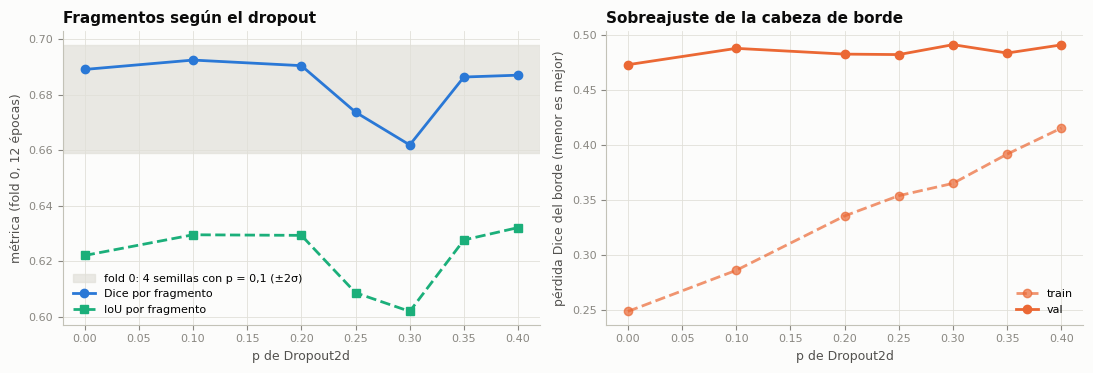

,"Δ Dice vs p = 0,1",Δ / σ semilla,dentro del rango de 4 semillas
p,,,
0.00,-0.0034,-0.3460,True
0.10,0.0000,0.0000,True
0.20,-0.0020,-0.2066,True
0.25,-0.0188,-1.9239,True
0.30,-0.0306,-3.1344,False
0.35,-0.0061,-0.6263,True
0.40,-0.0054,-0.5577,True


In [20]:
if not drop.empty and drop.p.max() >= 0.25:
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
    ax = axes[0]
    m, s = semillas["Dice frag"].mean(), SIGMA12
    ax.axhspan(m - 2 * s, m + 2 * s, color=GRID, alpha=0.7, label="fold 0: 4 semillas con p = 0,1 (±2σ)")
    d = drop.sort_values("p")
    ax.plot(d.p, d["Dice frag"], "o-", color=C["SA"], label="Dice por fragmento")
    ax.plot(d.p, d["IoU frag"], "s--", color=C["RI"], label="IoU por fragmento")
    ax.set(xlabel="p de Dropout2d", ylabel="métrica (fold 0, 12 épocas)")
    ax.set_title("Fragmentos según el dropout", loc="left")
    ax.legend()
    ax = axes[1]
    ax.plot(d.p, d["pérdida borde train"], "o--", color=C["LI"], alpha=0.7, label="train")
    ax.plot(d.p, d["pérdida borde val"], "o-", color=C["LI"], label="val")
    ax.set(xlabel="p de Dropout2d", ylabel="pérdida Dice del borde (menor es mejor)")
    ax.set_title("Sobreajuste de la cabeza de borde", loc="left")
    ax.legend()
    fig.tight_layout()
    savefig(fig, "05_dropout")
    plt.show()

    ref01 = drop.set_index("p")["Dice frag"]
    res = pd.DataFrame({"Δ Dice vs p = 0,1": ref01 - ref01[0.1], "Δ / σ semilla": (ref01 - ref01[0.1]) / SIGMA12,
                        "dentro del rango de 4 semillas": ref01.between(semillas["Dice frag"].min(), semillas["Dice frag"].max())})
    display(res.round(4))

- **No hay tendencia.** El Dice baja en 0,25 y 0,30 (0,674 y 0,662) y vuelve a subir en 0,35 y 0,40 (0,686 y 0,687). Si el dropout tuviera efecto, la curva iría en una sola dirección.
- Casi todos los puntos caen dentro del rango de las 4 semillas con p = 0,1 (0,670 a 0,693). Solo 0,30 queda fuera (−3σ), pero 0,35 y 0,40 vuelven al rango: con un solo fold, lo más probable es que sea ruido.
- La brecha de la pérdida de borde entre train y val sí se cierra (de 0,22 con p = 0 a 0,08 con p = 0,40), pero porque **empeora el train** (0,25 → 0,42); la de validación se queda en 0,47-0,49. El dropout frena el aprendizaje del borde sin hacerlo generalizar mejor.
- **Se queda p = 0,1.** Entre 0 y 0,40 el dropout espacial no cambia de forma medible la segmentación de fragmentos; lo que sí mide el ruido es la semilla.

## 18. Ensamble y TTA: atacar la varianza

Si cambiar solo la semilla mueve la métrica más que cualquier ajuste, parte del error es **varianza**: cada entrenamiento se equivoca en sitios distintos. Se probaron dos formas de promediar, sin reentrenar nada:

- **Ensamble:** promediar P(borde) y votar la región de varios modelos ya entrenados (`scripts/ensemble_oof.py`). De 2 modelos (misma config, semillas 42 y 1337) y de 6 (base ×2, c05, sin TL ×2, sin CBAM).
- **TTA (test-time augmentation):** el **mismo** modelo predice cada corte 5 veces con cambios leves (escala 0,92 y 1,08, rotación ±8°, dentro de la aumentación con la que se entrenó), se deshace cada cambio y se promedian las probabilidades (`pengwin/inference/volume.py`). También una versión de 9 pasadas que suma traslaciones de ±4 %.

Cada uno se combina con el posproceso de siempre (`edt`) y con F2C2. Referencia: el mismo modelo de una sola pasada.

In [21]:
FILAS9 = [  # (nombre, archivo, referencia, filtro)
    ("Ensamble 2 semillas", "pp_ens2_base", "pp1_base_e20", None),
    ("Ensamble 2 semillas + F2C2", "pp_ens2_base_hmax", "pp1_base_e20", None),
    ("Ensamble 6 modelos", "pp_ens6_todos", "pp1_base_e20", None),
    ("Ensamble 6 modelos + F2C2", "pp_ens6_todos_hmax", "pp1_base_e20", None),
    ("TTA 5 (semilla 42)", "pp_tta_base", "pp1_base_e20", None),
    ("TTA 5 + F2C2 (semilla 42)", "pp_tta_base_hmax", "pp1_base_e20", None),
    ("TTA 5 (semilla 1337)", "pp_tta_s1337", "pp1_c00b_seed1337_e20", None),
    ("TTA 5 + F2C2 (semilla 1337)", "pp_tta_s1337_hmax", "pp1_c00b_seed1337_e20", None),
    ("TTA 9 (semilla 42)", "pp_tta9_base", "pp1_base_e20", None),
    ("TTA 9 + F2C2 (semilla 42)", "pp_tta9_base_hmax", "pp1_base_e20", None),
]
filas, P9 = {}, {}
for nombre, arch, refn, filtro in FILAS9:
    f, prm = mejor(arch, filtro=filtro)
    if f is None:
        continue
    r, _ = mejor(refn)
    P9[nombre] = f
    pr = pareado(f, r)
    filas[nombre] = {"Dice frag": f.dice_fragmento.mean(), "IoU frag": f.iou_fragmento.mean(),
                     "Dice principal": f.dice_principal.mean(), "Secundarios %": f["recuperados_secundarios_%"].mean(),
                     "Δ Dice": pr["Δ"], "t": pr["t"], "folds a favor": pr["folds a favor"],
                     "Δ IoU": pareado(f, r, "iou_fragmento")["Δ"], "Δ principal": pareado(f, r, "dice_principal")["Δ"],
                     "posproceso": ", ".join(f"{k}={v}" for k, v in prm.items())}
var = pd.DataFrame(filas).T
display(pd.concat([ref_row, var]).round(4).fillna(""))

,Dice frag,IoU frag,Dice principal,Secundarios %,Δ Dice,t,folds a favor,Δ IoU,Δ principal,posproceso
"Referencia (base, semilla 42)",0.7453,0.6828,0.9206,59.5101,,,,,,
Ensamble 2 semillas,0.7570,0.6934,0.9228,61.4025,0.0117,1.7466,3/5,0.0106,0.0022,"method=edt, seed_depth_mm=5.0, edge_threshold=0.1"
Ensamble 2 semillas + F2C2,0.7849,0.7092,0.9118,65.9283,0.0396,3.7664,5/5,0.0264,-0.0088,"method=edt_hmax, seed_depth_mm=5.0, edge_thres..."
Ensamble 6 modelos,0.7788,0.7182,0.9298,64.8976,0.0335,4.1894,5/5,0.0354,0.0092,"method=edt, seed_depth_mm=5.0, edge_threshold=0.1"
Ensamble 6 modelos + F2C2,0.7975,0.7245,0.9156,66.9368,0.0522,3.2847,5/5,0.0416,-0.005,"method=edt_hmax, seed_depth_mm=5.0, edge_thres..."
TTA 5 (semilla 42),0.7638,0.7009,0.9236,63.9577,0.0185,2.3477,4/5,0.018,0.003,"method=edt, seed_depth_mm=5.0, edge_threshold=0.1"
TTA 5 + F2C2 (semilla 42),0.7922,0.7167,0.9143,67.8980,0.0469,4.1337,5/5,0.0339,-0.0063,"method=edt_hmax, seed_depth_mm=5.0, edge_thres..."
TTA 5 (semilla 1337),0.7533,0.6919,0.9229,59.6907,0.0087,0.8448,3/5,0.0233,0.0255,"method=edt, seed_depth_mm=5.0, edge_threshold=0.1"
TTA 5 + F2C2 (semilla 1337),0.7812,0.7081,0.9134,65.6029,0.0366,3.6576,4/5,0.0394,0.016,"method=edt_hmax, seed_depth_mm=5.0, edge_thres..."
TTA 9 (semilla 42),0.7491,0.6871,0.9207,60.4306,0.0038,0.8605,3/5,0.0043,0.0001,"method=edt, seed_depth_mm=5.0, edge_threshold=0.1"


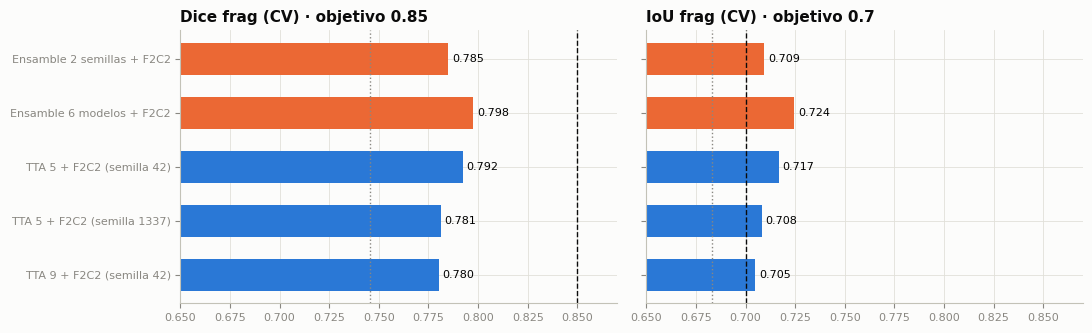

In [22]:
orden = ["Ensamble 2 semillas + F2C2", "Ensamble 6 modelos + F2C2", "TTA 5 + F2C2 (semilla 42)", "TTA 5 + F2C2 (semilla 1337)",
         "TTA 9 + F2C2 (semilla 42)"]
orden = [o for o in orden if o in var.index]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
y = np.arange(len(orden))[::-1]
for ax, col, obj in ((axes[0], "Dice frag", 0.85), (axes[1], "IoU frag", 0.70)):
    ref_v = ref_row[col].iloc[0]
    ax.barh(y, var.loc[orden, col].astype(float), color=[C["LI"] if "Ensamble" in o else C["SA"] for o in orden], height=0.6)
    ax.axvline(ref_v, color=MUTED, lw=1, ls=":")
    ax.axvline(obj, color=INK, lw=1, ls="--")
    ax.set_xlim(0.65, max(0.87, obj + 0.02))
    ax.set_title(f"{col} (CV) · objetivo {obj}", loc="left")
    for yi, v in zip(y, var.loc[orden, col].astype(float)):
        ax.text(v + 0.002, yi, f"{v:.3f}", va="center", fontsize=8)
axes[0].set_yticks(y, orden)
fig.tight_layout()
savefig(fig, "06_ensamble_tta")
plt.show()

- **Promediar sí ayuda, y es lo primero que se mueve por encima del ruido.** TTA de 5 pasadas + F2C2 sube el Dice +0,047 (t = 4,1, 5/5 folds) con la semilla 42 y +0,037 (4/5) con la 1337. El IoU pasa de 0,70 en las dos.
- **TTA es mejor que un ensamble de 2 modelos** (0,792 contra 0,785 de Dice) y casi iguala al de 6 (0,798). Promediar versiones del mismo modelo rinde lo mismo que entrenar más modelos.
- **El ensamble se descarta por el enunciado:** pide "tres cabezas sobre un mismo backbone", y un ensamble usa varios. TTA usa un solo modelo y no cambia la detección ni la clasificación.
- **TTA de 9 pasadas es peor que el de 5** (−0,012): las traslaciones emborronan el borde. Se queda el de 5.
- Con TTA, el Dice del fragmento principal baja poco (−0,006 con la semilla 42), dentro del límite de 0,010 que se había fijado para F2C2.

## 19. Modelo final

Configuración final, elegida solo con validación cruzada (`configs/tuned.yaml`):

- **Modelo:** `v2_last`, sin reentrenar. Arquitectura y entrenamiento iguales a `base.yaml` (FundidoraPC residual + CBAM en bloques 3-4 + 3 cabezas, dropout 0,1, con transfer learning).
- **Inferencia:** TTA de 5 pasadas (sección 18).
- **Posproceso:** `edt_hmax` (F2C2), profundidad 5 mm, umbral de borde 0,1, h = 1,5 mm.

F2C2 se adopta **después** de ver los datos: la regla fijada de antemano lo había dejado fuera por 0,0012 en una réplica. Se declara así. Con TTA cumple esa misma regla.

Se midió en test **una sola vez**. Como el IoU quedó a 0,003 del objetivo, después se intentó afinar por CV (sin volver a mirar el test) el posproceso con TTA. Resultados en la última tabla:

- `min_fragment_cm3` y `seed_min_cm3` no cambian nada: con `edt_hmax` no son los que generan los fragmentos de más.
- Profundidad 5,5 mm sube el Dice (+0,009 de media) pero el IoU casi no se mueve (+0,003: mejora con una semilla y empeora con la otra) y baja otra vez el principal. No se adopta.

Por eso no hubo segunda medición en test. (El barrido de `seed_min_cm3` se corrió en el PC local, con otras versiones de las librerías, y en el mismo punto da 0,002 menos que en la DGX Spark.)

In [23]:
fin = REP / "fragments" / "v2_last_test_tuned.json"
antes = read_json(REP / "fragments" / "v2_last_test_edt.json")["global"]
if not fin.exists():
    print("Pendiente: la evaluación en test todavía no ha terminado.")
else:
    d = read_json(fin)
    g = d["global"]
    print("posproceso:", d.get("postproceso"), "· TTA:", d.get("tta"))
    filas = [("Clasificación", "F1", ev["cls_f1_macro"], ev["cls_f1_macro"], 0.85),
             ("Clasificación", "AUC", ev["cls_auc_macro"], ev["cls_auc_macro"], 0.85),
             ("Detección", "IoU promedio", ev["IoU_promedio"], ev["IoU_promedio"], 0.65),
             ("Detección", "mAP@0.50", ev["mAP@0.50"], ev["mAP@0.50"], 0.65),
             ("Detección", "mAP@[.50:.95]", ev["mAP@[.50:.95]"], ev["mAP@[.50:.95]"], 0.40),
             ("Fragmento", "Dice", antes["dice_fragmento"], g["dice_fragmento"], 0.85),
             ("Fragmento", "IoU", antes["iou_fragmento"], g["iou_fragmento"], 0.70),
             ("Fragmento", "Dice principal", antes["dice_principal"], g["dice_principal"], np.nan),
             ("Fragmento", "Dice secundario", antes["dice_secundario"], g["dice_secundario"], np.nan),
             ("Fragmento", "Secundarios recuperados %", antes["recuperados_secundarios_%"], g["recuperados_secundarios_%"], np.nan)]
    final = pd.DataFrame(filas, columns=["Tarea", "Métrica", "Antes (semana 10)", "Final", "Objetivo"])
    final["Cumple"] = np.where(final.Objetivo.isna(), "", np.where(final.Final >= final.Objetivo, "sí", "no"))
    # 0,697 frente a 0,70 con un IC95 de 0,636-0,753 (bootstrap de pacientes, 03_semana11 §10.3): no se puede afirmar.
    final.loc[(final.Tarea == "Fragmento") & (final.Métrica == "IoU"), "Cumple"] = "no concluyente"
    display(final.round(3).fillna(""))

posproceso: {'instance_method': 'edt_hmax', 'edge_threshold': 0.1, 'min_fragment_cm3': 0.1, 'max_fragments': 10, 'seed_depth_mm': 5.0, 'seed_min_cm3': 0.02, 'edge_weight': 5.0, 'core_threshold': 0.5, 'core_seed_depth_mm': 0.0, 'hmax_h_mm': 1.5, 'dist_max_mm': 8.0} · TTA: 5


,Tarea,Métrica,Antes (semana 10),Final,Objetivo,Cumple
0,Clasificación,F1,0.993,0.993,0.85,sí
1,Clasificación,AUC,0.999,0.999,0.85,sí
2,Detección,IoU promedio,0.919,0.919,0.65,sí
3,Detección,mAP@0.50,0.980,0.980,0.65,sí
4,Detección,mAP@[.50:.95],0.864,0.864,0.4,sí
5,Fragmento,Dice,0.725,0.768,0.85,no
6,Fragmento,IoU,0.671,0.697,0.7,no concluyente
7,Fragmento,Dice principal,0.930,0.924,,
8,Fragmento,Dice secundario,0.489,0.588,,
9,Fragmento,Secundarios recuperados %,51.282,56.410,,


In [24]:
lat = {"sin TTA": REP / "latency" / "v2_last.json", "con TTA (final)": REP / "latency" / "v2_last_tta.json"}
filas = {}
for k, f in lat.items():
    if f.exists():
        l = read_json(f)
        filas[k] = {"CPU fp32 (ms/corte)": l["cpu_fp32"]["media_ms"], "GPU fp32 (ms/corte)": l["gpu_fp32"]["media_ms"],
                    "GPU AMP (ms/corte)": l["gpu_amp"]["media_ms"], "volumen completo GPU (s)": l["gpu_volumen_completo_s"],
                    "cortes": l["cortes_volumen"], "GPU": l["gpu"]}
pd.DataFrame(filas).T.round(1)

,CPU fp32 (ms/corte),GPU fp32 (ms/corte),GPU AMP (ms/corte),volumen completo GPU (s),cortes,GPU
sin TTA,66.1853,7.7102,10.3432,2.7568,401,NVIDIA GeForce RTX 3060 Laptop GPU
con TTA (final),308.6487,33.7952,37.9243,7.4084,401,NVIDIA GeForce RTX 3060 Laptop GPU


In [25]:
# Intentos de afinar el posproceso con TTA por CV (sin mirar el test): IoU por fragmento, media de 5 folds
fin_cv = []
for t, sem in (("base", 42), ("s1337", 1337)):
    for arch, k in ((f"pp_tta_{t}_fino", "seed_depth_mm"), (f"pp_tta_{t}_fino", "min_fragment_cm3"), (f"pp_tta_{t}_seedmin", "seed_min_cm3")):
        d = pp(arch)
        if d is None:
            continue
        if "fino" in arch:
            d = d[d.hmax_h_mm == 1.5]
            d = d[d.min_fragment_cm3 == 0.1] if k == "seed_depth_mm" else d[d.seed_depth_mm == 5.0]
        for v, g in d.groupby(k):
            fin_cv.append({"semilla": sem, "parámetro": k, "valor": v, "Dice frag": g.dice_fragmento.mean(), "IoU frag": g.iou_fragmento.mean()})
pd.DataFrame(fin_cv).set_index(["parámetro", "valor", "semilla"]).unstack("semilla").round(4)

Dice frag         IoU frag        
semilla                     42      1337     42      1337
parámetro        valor                                   
min_fragment_cm3 0.10     0.7922  0.7812   0.7167  0.7081
                 0.50     0.7922  0.7812   0.7167  0.7081
                 1.00     0.7922  0.7812   0.7167  0.7081
seed_depth_mm    4.50     0.7694  0.7713   0.7020  0.7043
                 5.00     0.7922  0.7812   0.7167  0.7081
                 5.50     0.7953  0.7957   0.7150  0.7152
seed_min_cm3     0.02     0.7903  0.7792   0.7149  0.7063
                 0.05     0.7902  0.7792   0.7149  0.7063
                 0.10     0.7902  0.7792   0.7148  0.7063
                 0.20     0.7902  0.7787   0.7148  0.7060
                 0.50     0.7892  0.7770   0.7141  0.7044

# Parte C. Decisiones

## 20. Registro de decisiones

Todo lo que se construyó o se probó en la semana 10, con la evidencia y lo que se hizo con ello. "CV" = validación cruzada de 5 folds por paciente; σ = ruido de semilla.

| # | Intento | Qué buscaba | Evidencia | Decisión |
|---|---|---|---|---|
| 1 | Modelo v2: borde 3D, Dropout2d 0,1, γ, λ recalibrados | cajas más finas y medir cada componente | test mAP@[.5:.95] 0,841 → 0,864 | **adoptado** |
| 2 | Separar solo por borde | fragmentos desde el borde predicho | 13 % de secundarios en test; el oráculo muestra que falla el borde | descartado |
| 3 | Separar por distancia (`edt`), semilla a 5 mm | no depender de un borde que se pierde | val: 1,8 % → 67 % de secundarios | **adoptado** |
| 4 | 10 hiperparámetros (peso y grosor del borde, lr, dropout, aumentación, lr del backbone, sobremuestreo) | mejorar el borde | 9 dentro de ±2σ; lr del backbone × 0,3 empeora (−0,042) | descartados |
| 5 | Sobremuestrear cortes con secundarios (c05) | más ejemplos de lo difícil | CV +0,009, t = 0,94 | descartado |
| 6 | Cabeza núcleo/borde (F2B1) | representación del ganador del challenge | CV −0,072 (t = −3,1); el mismo modelo con `edt`: +0,001 | descartado |
| 7 | Cabeza de mapa de distancia (F2B2) | predecir la distancia a la fractura | CV −0,241; con `edt`: −0,016, dentro del ruido | descartado |
| 8 | Semillas por h-máxima solas (F2C1) | no perder fragmentos pequeños | Dice +0,015 pero principal −0,043 e IoU +0,001 | descartado |
| 9 | `edt` + rescate por h-máxima (F2C2), h = 1,5 | ídem, sin perder lo de `edt` | CV +0,020 a +0,029, 4-5 de 5 folds, con 2 semillas | **adoptado** (declarado después de ver los datos) |
| 10 | Sin CBAM / sin transfer learning | ablación del §7 | dentro del ruido (t = −0,92; sin TL con 2 semillas: t = 1,23) | CBAM se mantiene por el enunciado; TL se mantiene (neutro) |
| 11 | Dropout espacial 0 a 0,40 | frenar el sobreajuste del borde | sin tendencia; la brecha se cierra porque empeora el train | se queda 0,1 |
| 12 | Ensamble de 2 y de 6 modelos | reducir varianza | CV con F2C2 0,785 y 0,798 (sin F2C2, 0,757 y 0,779) | descartado: el §4.1 pide un mismo backbone |
| 13 | TTA de 5 pasadas | reducir varianza con un solo modelo | CV: TTA solo +0,019 (t = 2,35, 4/5); con F2C2, +0,047 (t = 4,1, 5/5) | **adoptado** |
| 14 | TTA de 9 pasadas (con traslaciones) | ídem | −0,012 contra TTA 5 | descartado |
| 15 | Afinar `min_fragment_cm3`, `seed_min_cm3`, profundidad 5,5 mm | cerrar los 0,003 de IoU | sin efecto o mixto entre semillas | descartado, sin segunda medición en test |

Configuración resultante: `configs/tuned.yaml` (modelo v2_last + TTA 5 + F2C2). Lo que se probó en la semana 11 está en `03_semana11.ipynb`.

## 21. Uso del test

Estas son todas las veces que se evaluó el test (15 pacientes, `splits.json`).

**Dos decisiones anteriores al ajuste sí miraron el test**, y se declaran: (1) se entregó la última época de `v2` (39) en vez de la mejor en validación (22) después de ver en test que tenía mejores cajas finas (mAP@[.50:.95] 0,864 contra 0,848; el Dice por fragmento de las dos es el mismo, 0,533); (2) los diagnósticos de la sección 3 (oráculo del borde y cruce de región y borde reales) se calcularon en test y motivaron pasar el borde a 3D y separar por distancia. El parámetro de esa separación (5 mm) se eligió en validación, y la validación cruzada confirmó después el cambio por su cuenta (+0,247 de Dice por fragmento). **Desde el ajuste (parte B) el test no se usó para elegir nada.**

| Cuándo | Qué se midió | Para qué |
|---|---|---|
| Semana 9 | base, sin CBAM, sin TL (detección, clasificación, región) | ablación del §7 (después se repitió por CV, sección 16) |
| Semana 10 | v2 y v2_last; fragmentos solo borde y `edt`; oráculos de borde y región; SAM; latencia | resultados de la semana (secciones 2-8); **influyó** en la época entregada y en pasar a la separación por distancia |
| Ajuste | `configs/tuned.yaml`, **una vez** | resultado final (sección 19) |
| Avance del 2 de octubre | prueba de estrés de la detección (`scripts/stress_detection.py`) | revisar si el mAP alto era real; no cambia el modelo |
| Semana 11 | la misma `tuned.yaml`, guardando las predicciones y con HD95/ASSD | galería de peores casos y métricas opcionales; no cambia el modelo |

**Conclusión de la semana.** Con el mismo modelo, cambiando solo la inferencia (TTA) y el posproceso (F2C2), el test pasa de Dice 0,725 a 0,768 y de IoU 0,671 a 0,697. Detección y clasificación cumplen con margen. El límite está en la cabeza de borde, que encuentra menos del 20 % de la superficie de fractura: con el borde real el Dice sería 0,90 en validación cruzada. Ningún hiperparámetro lo movió por encima del ruido; lo que sí funcionó fue reducir la varianza y no perder semillas.